# Tugas Praproses Data
**Nama:** Rakha Makarim  
**NIM:** 5054251010  

Dataset: Ames Housing (1460 rumah, target `SalePrice`).

Tahapan:
1. Pembersihan Data
2. Deteksi dan Penanganan Outlier
3. Transformasi Data (normalisasi + one-hot encoding)
4. Reduksi Dimensi (korelasi + PCA)

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")

In [ ]:
df = pd.read_csv("dataset/Train.csv")
print("Shape:", df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [104]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 76 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   float64
 1   MSSubClass     1460 non-null   float64
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   float64
 5   Street         1460 non-null   str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   float64
 17  OverallCond    1460 non-null   float64
 18  YearBuilt      1460

## 1. Pembersihan Data

### 1.1 Jumlah nilai hilang pada setiap atribut

In [90]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"jumlah_hilang": missing, "proporsi_%": missing_pct})
missing_table[missing_table["jumlah_hilang"] > 0].sort_values("proporsi_%", ascending=False)

,jumlah_hilang,proporsi_%
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### 1.2 Hapus kolom dengan nilai hilang > 50%

In [91]:
drop_cols = missing_pct[missing_pct > 50].index.tolist()
print("Kolom dihapus (>50% hilang):", drop_cols)
df = df.drop(columns=drop_cols)
print("Shape setelah dihapus:", df.shape)

Kolom dihapus (>50% hilang): ['Alley', 'MasVnrType', 'PoolQC', 'Fence', 'MiscFeature']
Shape setelah dihapus: (1460, 76)


### 1.3 Tangani sisa nilai hilang

Atribut numerik diisi **median**, atribut kategoris diisi **modus** (nilai paling sering muncul).

In [92]:
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            m = df[col].mode()
            if not m.empty:
                df[col] = df[col].fillna(m[0])

print("Sisa nilai hilang:", df.isnull().sum().sum())

Sisa nilai hilang: 0


## 2. Deteksi dan Penanganan Outlier

### 2.1 Boxplot atribut numerik

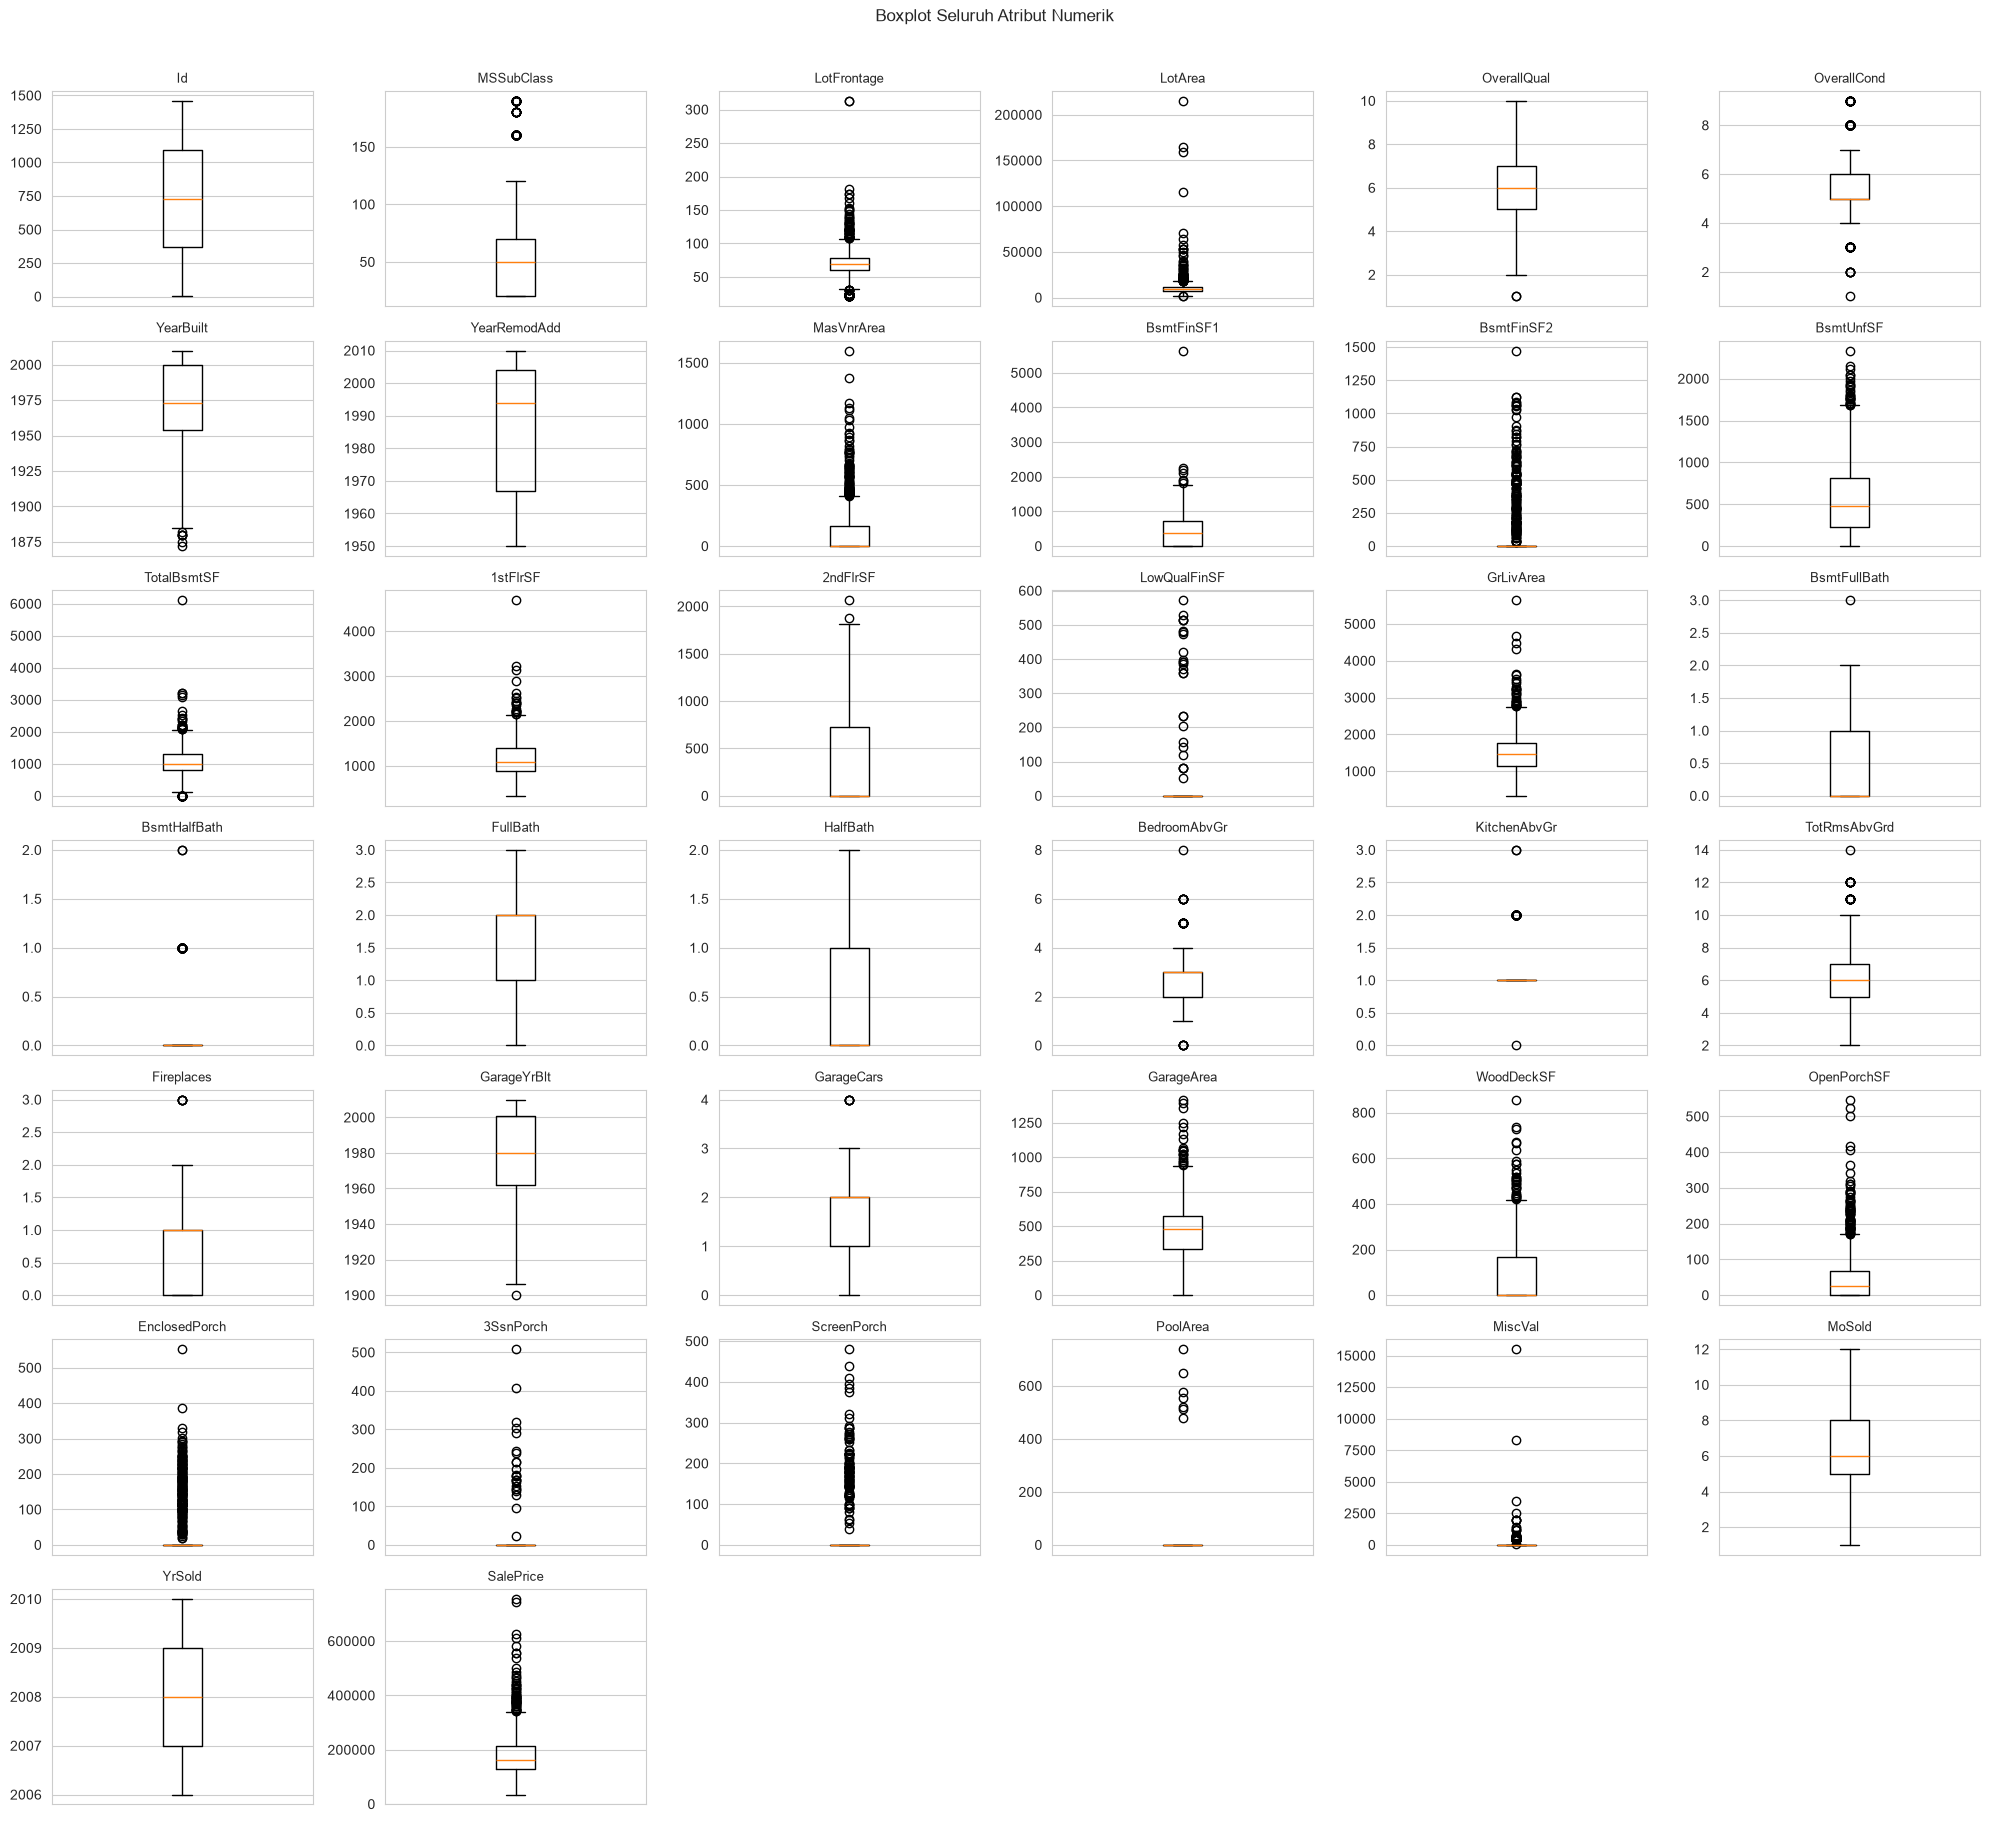

In [93]:
num_cols = df.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(7, 6, figsize=(20, 18))
for ax, col in zip(axes.flatten(), num_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
for ax in axes.flatten()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle("Boxplot Seluruh Atribut Numerik", y=1.01)
plt.tight_layout()
plt.show()

In [94]:
def count_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_counts = df[num_cols].apply(count_outliers).sort_values(ascending=False)
outlier_counts[outlier_counts > 0]

EnclosedPorch    208
BsmtFinSF2       167
OverallCond      125
ScreenPorch      116
LotFrontage      106
MSSubClass       103
MasVnrArea        98
BsmtHalfBath      82
OpenPorchSF       77
LotArea           69
KitchenAbvGr      68
TotalBsmtSF       61
SalePrice         61
MiscVal           52
BedroomAbvGr      35
WoodDeckSF        32
GrLivArea         31
TotRmsAbvGrd      30
BsmtUnfSF         29
LowQualFinSF      26
3SsnPorch         24
GarageArea        21
1stFlrSF          20
BsmtFinSF1         7
YearBuilt          7
PoolArea           7
GarageCars         5
Fireplaces         5
2ndFlrSF           2
OverallQual        2
BsmtFullBath       1
GarageYrBlt        1
dtype: int64

### 2.2 Penanganan outlier

**Keputusan: outlier disesuaikan (dicapping ke batas IQR), bukan dihapus.**

Alasan: outlier pada data rumah (misal `LotArea`, `SalePrice` sangat besar) sebagian besar adalah rumah mewah yang **valid**, bukan kesalahan pencatutan. Menghapusnya akan mengurangi jumlah data dan menghilangkan informasi harga tinggi yang justru penting. Dengan dicapping, data tetap utuh dan distribusi tetap wajar.

In [95]:
skipped_cols = []
for col in num_cols:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    if iqr == 0:
        skipped_cols.append(col)
        continue
    df[col] = df[col].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

print("Kolom di-skip (IQR=0, mayoritas nilainya sama):", skipped_cols)
df[num_cols].apply(count_outliers).sum()

Kolom di-skip (IQR=0, mayoritas nilainya sama): ['BsmtFinSF2', 'LowQualFinSF', 'BsmtHalfBath', 'KitchenAbvGr', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal']


np.int64(750)

## 3. Transformasi Data

### 3.1 Standarisasi atribut numerik (zero mean, unit variance)

In [96]:
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
df[num_cols].describe().round(2)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,...,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00
mean,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,...,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.73,-0.94,-2.18,-2.27,-2.98,-2.12,-2.87,-1.69,-0.67,-1.02,...,-0.79,-0.81,-0.36,-0.12,-0.27,-0.07,-0.09,-1.97,-1.37,-2.12
25%,-0.87,-0.94,-0.53,-0.58,-0.80,-0.56,-0.57,-0.87,-0.67,-1.02,...,-0.79,-0.81,-0.36,-0.12,-0.27,-0.07,-0.09,-0.49,-0.61,-0.70
50%,0.00,-0.14,-0.01,-0.05,-0.07,-0.56,0.06,0.44,-0.67,-0.13,...,-0.79,-0.34,-0.36,-0.12,-0.27,-0.07,-0.09,-0.12,0.14,-0.21
75%,0.87,0.40,0.58,0.54,0.65,0.47,0.95,0.93,0.56,0.63,...,0.65,0.48,-0.36,-0.12,-0.27,-0.07,-0.09,0.62,0.89,0.55
max,1.73,2.40,2.23,2.23,2.83,2.03,1.29,1.22,2.40,3.10,...,2.81,2.43,8.68,17.22,8.34,18.31,31.17,2.10,1.65,2.42


### 3.2 One-hot encoding atribut kategoris

In [97]:
cat_cols = df.select_dtypes(include="object").columns
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Shape setelah encoding:", df_encoded.shape)
df_encoded.head()

Shape setelah encoding: (1460, 235)


/tmp/ipykernel_15044/3781896419.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,-1.730865,0.131067,-0.237456,-0.333244,0.652644,-0.564161,1.053246,0.878668,0.795643,0.614224,...,False,False,False,False,True,False,False,False,True,False
1,-1.728492,-0.935733,0.633321,-0.013189,-0.073068,2.030907,0.156179,-0.429577,-0.667353,1.242296,...,False,False,False,False,True,False,False,False,True,False
2,-1.726120,0.131067,-0.063300,0.446022,0.652644,-0.564161,0.986797,0.830215,0.541858,0.106224,...,False,False,False,False,True,False,False,False,True,False
3,-1.723747,0.397766,-0.527714,-0.027104,0.652644,-0.564161,-1.870528,-0.720298,-0.667353,-0.517230,...,False,False,False,False,True,False,False,False,False,False
4,-1.721374,0.131067,0.865528,1.283733,1.378355,-0.564161,0.953572,0.733308,1.945140,0.496460,...,False,False,False,False,True,False,False,False,True,False


## 4. Reduksi Dimensi

### 4.1 Analisis korelasi

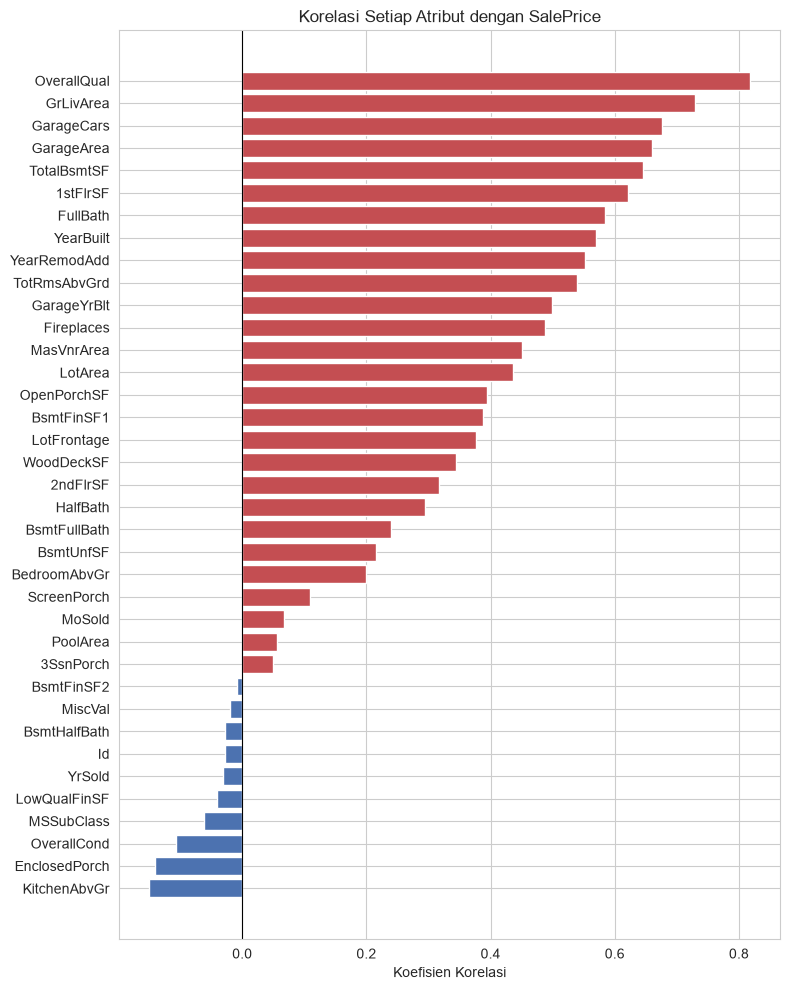

In [98]:
target_corr = df[num_cols].corr()["SalePrice"].drop("SalePrice").sort_values()
colors = ["#4C72B0" if v < 0 else "#C44E52" for v in target_corr]

plt.figure(figsize=(8, 10))
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Korelasi Setiap Atribut dengan SalePrice")
plt.xlabel("Koefisien Korelasi")
plt.tight_layout()
plt.show()

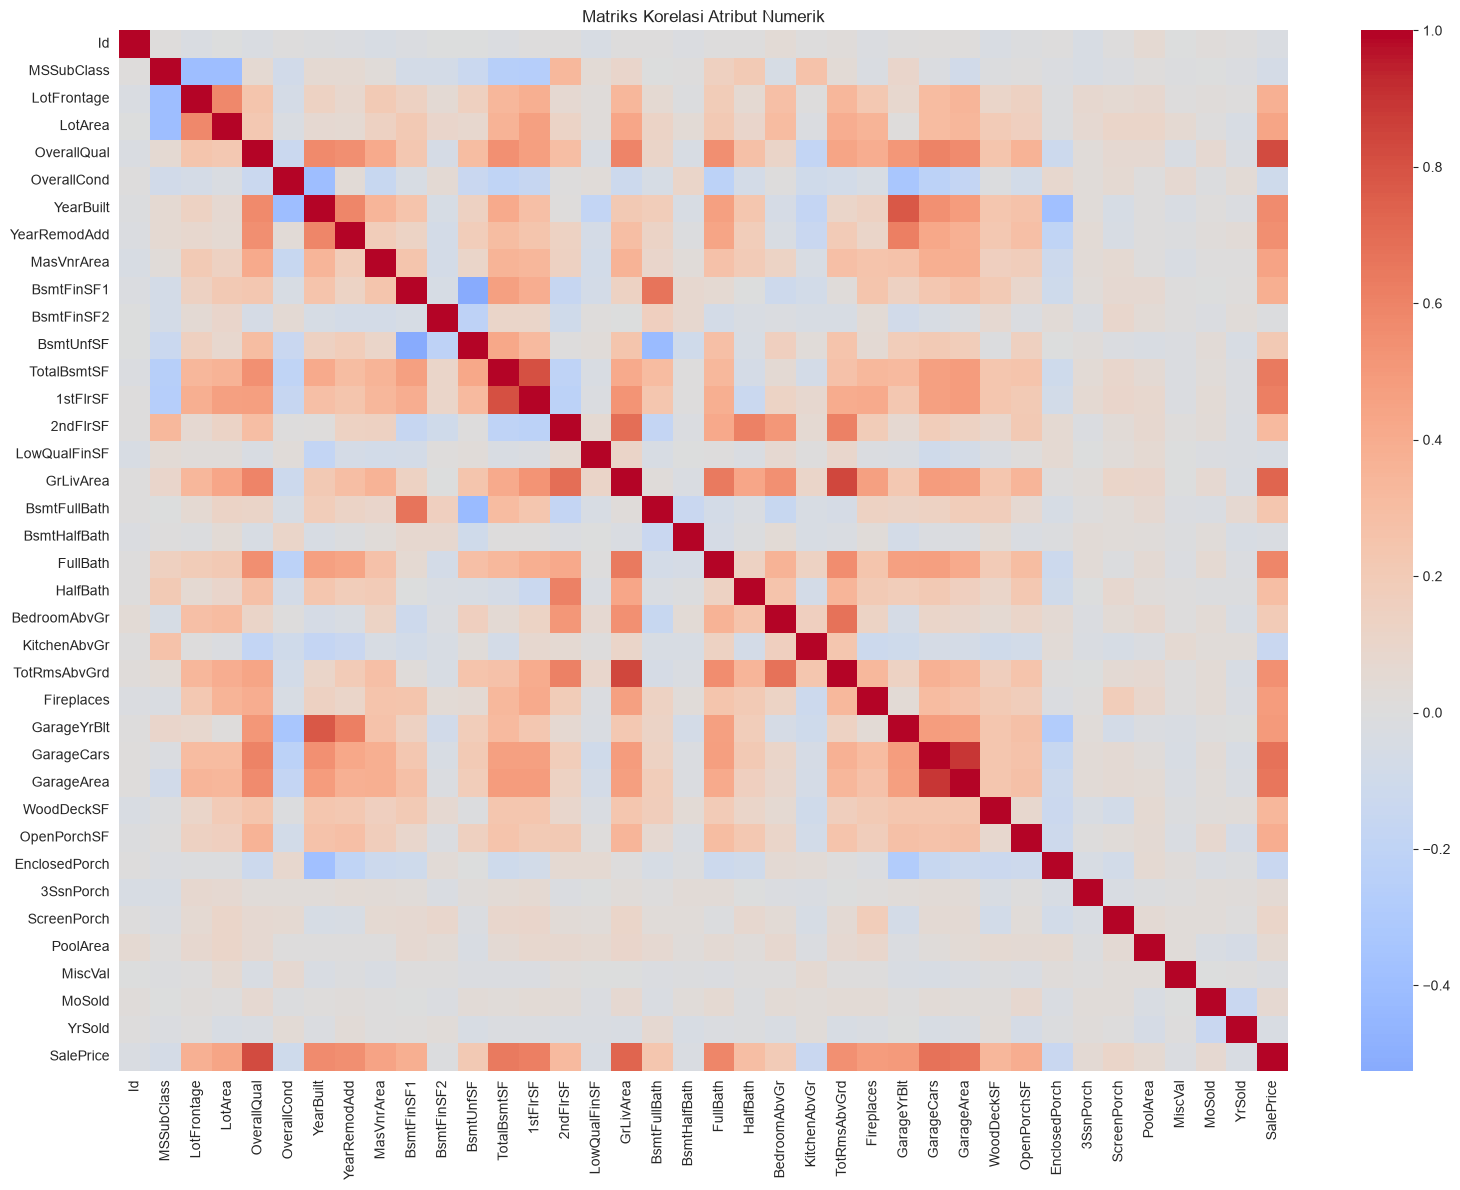

In [107]:
plt.figure(figsize=(16, 12))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Matriks Korelasi Atribut Numerik")
plt.tight_layout()
plt.show()

In [99]:
# Buang salah satu dari pasangan atribut yang berkorelasi sangat tinggi (|r| > 0.9)
corr = df_encoded.corr(numeric_only=True)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [col for col in upper.columns if (abs(upper[col]) > 0.9).any()]

print("Dibuang karena korelasi > 0.9:", to_drop)
df_final = df_encoded.drop(columns=to_drop)
print("Shape setelah buang atribut korelasi tinggi:", df_final.shape)

Dibuang karena korelasi > 0.9: ['RoofStyle_Hip', 'Exterior2nd_CBlock', 'Exterior2nd_CmentBd', 'Exterior2nd_MetalSd', 'Exterior2nd_VinylSd', 'ExterQual_TA', 'SaleCondition_Partial']
Shape setelah buang atribut korelasi tinggi: (1460, 228)


### 4.2 Data akhir siap digunakan

In [100]:
print("Shape data akhir:", df_final.shape)
df_final.head()

Shape data akhir: (1460, 228)


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,SaleType_ConLD,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal
0,-1.730865,0.131067,-0.237456,-0.333244,0.652644,-0.564161,1.053246,0.878668,0.795643,0.614224,...,False,False,False,False,False,True,False,False,False,True
1,-1.728492,-0.935733,0.633321,-0.013189,-0.073068,2.030907,0.156179,-0.429577,-0.667353,1.242296,...,False,False,False,False,False,True,False,False,False,True
2,-1.726120,0.131067,-0.063300,0.446022,0.652644,-0.564161,0.986797,0.830215,0.541858,0.106224,...,False,False,False,False,False,True,False,False,False,True
3,-1.723747,0.397766,-0.527714,-0.027104,0.652644,-0.564161,-1.870528,-0.720298,-0.667353,-0.517230,...,False,False,False,False,False,True,False,False,False,False
4,-1.721374,0.131067,0.865528,1.283733,1.378355,-0.564161,0.953572,0.733308,1.945140,0.496460,...,False,False,False,False,False,True,False,False,False,True


### 4.3 Simpan data akhir ke CSV

In [101]:
df_final.to_csv("5054251010_Rakha_Makarim_Tugas_Praproses_Data.csv", index=False)

### 4.4 PCA (Principal Component Analysis)

Mempertahankan komponen yang menjelaskan 95% varians data.

In [105]:
X = df_final.drop(columns="SalePrice")
pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X.astype(float))

print("Dimensi sebelum PCA :", df_final.shape[1])
print("Dimensi setelah PCA :", X_pca.shape[1])
print("Varians terjelaskan :", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Dimensi sebelum PCA : 228
Dimensi setelah PCA : 65
Varians terjelaskan : 95.05 %


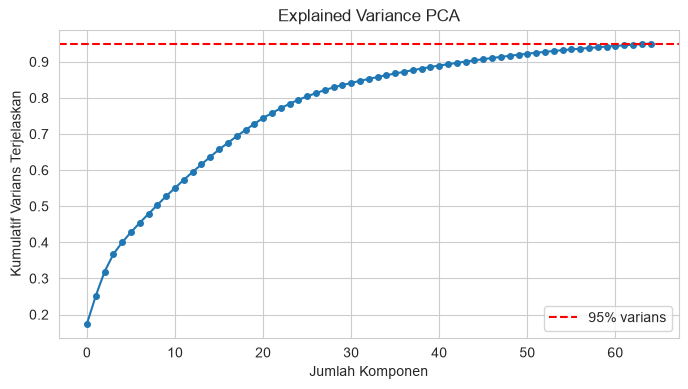

array([[ 2.13565051,  0.43116648, -2.25418322, ..., -0.25852689,
        -0.04133217,  0.19438684],
       [ 0.03651594, -1.4206726 ,  1.61027064, ..., -0.15627267,
        -0.29502268,  0.01058714],
       [ 2.55677017,  0.3034643 , -1.65204406, ..., -0.31534252,
        -0.03375937,  0.08317834],
       ...,
       [ 0.56832399,  3.31331051,  1.21280544, ..., -0.42199367,
        -0.09707817,  0.14823632],
       [-2.86743362, -2.3565414 ,  1.76796534, ..., -0.0094782 ,
         0.32912846,  0.21572756],
       [-1.33806824, -1.52131238,  1.65749012, ...,  0.11361038,
         0.61888078,  0.41746693]], shape=(1460, 65))

In [106]:
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o", ms=4)
plt.axhline(0.95, ls="--", c="red", label="95% varians")
plt.xlabel("Jumlah Komponen")
plt.ylabel("Kumulatif Varians Terjelaskan")
plt.title("Explained Variance PCA")
plt.legend()
plt.show()

X_pca